# ML Assignment 2: Obesity Level Classification

**Name:** TAMIL SELVI R
**ID:** 2025AJ05615

**Dataset:** Estimation of Obesity Levels Based on Eating Habits and Physical Condition  
**Source:** UCI Machine Learning Repository  
**Task:** Multiclass classification

## Objective
Build, evaluate, and compare five classification algorithms:
1. Logistic Regression
2. Decision Tree
3. K-Nearest Neighbors
4. Gaussian Naive Bayes
5. Support Vector Machine

The required metrics are **Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC)**.


## 1. Import libraries

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    classification_report, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
print('Libraries imported successfully.')

Libraries imported successfully.


## 2. Load the dataset

In [2]:
DATA_PATH = 'ObesityDataSet_raw_and_data_sinthetic.csv'

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Place the UCI CSV in the same folder as this notebook "
        "or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully.')
print('Dataset shape:', df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 3. Initial data understanding
Inspect size, columns, data types, numerical summaries, and categorical summaries before preprocessing.

In [3]:
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print('\nColumn names:')
print(df.columns.tolist())
print('\nData types and non-null counts:')
df.info()

Rows: 2111
Columns: 17

Column names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null

In [4]:
print('Numerical summary:')
display(df.describe().T)

print('Categorical summary:')
display(df.describe(include='object').T)

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.312600,6.345968,14.00,19.947192,22.777890,26.000000,61.00
Height,2111.0,1.701677,0.093305,1.45,1.630000,1.700499,1.768464,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.000000,2.385502,3.000000,3.00
NCP,2111.0,2.685628,0.778039,1.00,2.658738,3.000000,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,1.584812,2.000000,2.477420,3.00
FAF,2111.0,1.010298,0.850592,0.00,0.124505,1.000000,1.666678,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.000000,0.625350,1.000000,2.00


Categorical summary:


,count,unique,top,freq
Gender,2111,2,Male,1068
family_history_with_overweight,2111,2,yes,1726
FAVC,2111,2,yes,1866
CAEC,2111,4,Sometimes,1765
SMOKE,2111,2,no,2067
SCC,2111,2,no,2015
CALC,2111,4,Sometimes,1401
MTRANS,2111,5,Public_Transportation,1580
NObeyesdad,2111,7,Obesity_Type_I,351


## 4. Data quality checks
Inspect missing values and exact duplicate rows before making any cleaning decision.

In [5]:
missing = df.isnull().sum().sort_values(ascending=False)
print('Missing values by column:')
display(missing.to_frame('missing_count'))
print('Total missing values:', int(missing.sum()))

n_duplicates = int(df.duplicated().sum())
print('Exact duplicate rows:', n_duplicates)

Missing values by column:


,missing_count
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


Total missing values: 0
Exact duplicate rows: 24


### Duplicate-handling decision

In [6]:
df_clean = df.drop_duplicates().reset_index(drop=True).copy()
print('Original shape:', df.shape)
print('Shape after removing exact duplicates:', df_clean.shape)
print('Rows removed:', len(df) - len(df_clean))

Original shape: (2111, 17)
Shape after removing exact duplicates: (2087, 17)
Rows removed: 24


## 5. Target variable analysis
`NObeyesdad` represents the obesity/weight class to predict. We inspect the number and distribution of classes.

In [7]:
TARGET = 'NObeyesdad'

class_counts = df_clean[TARGET].value_counts().sort_index()
class_pct = (df_clean[TARGET].value_counts(normalize=True).sort_index() * 100).round(2)

target_summary = pd.DataFrame({'Count': class_counts, 'Percentage': class_pct})
display(target_summary)
print('Number of target classes:', df_clean[TARGET].nunique())
print('Classes:', sorted(df_clean[TARGET].unique()))

,Count,Percentage
NObeyesdad,,
Insufficient_Weight,267,12.79
Normal_Weight,282,13.51
Obesity_Type_I,351,16.82
Obesity_Type_II,297,14.23
Obesity_Type_III,324,15.52
Overweight_Level_I,276,13.22
Overweight_Level_II,290,13.90


Number of target classes: 7
Classes: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight_Level_I', 'Overweight_Level_II']


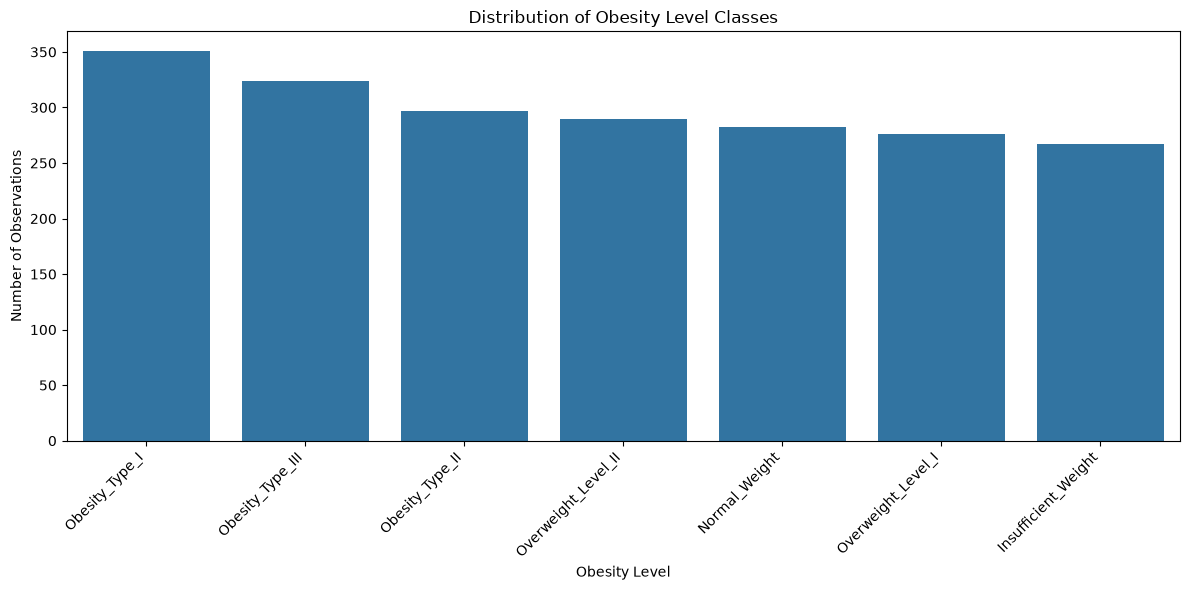

In [8]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df_clean, x=TARGET, order=df_clean[TARGET].value_counts().index)
plt.title('Distribution of Obesity Level Classes')
plt.xlabel('Obesity Level')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6. Exploratory Data Analysis


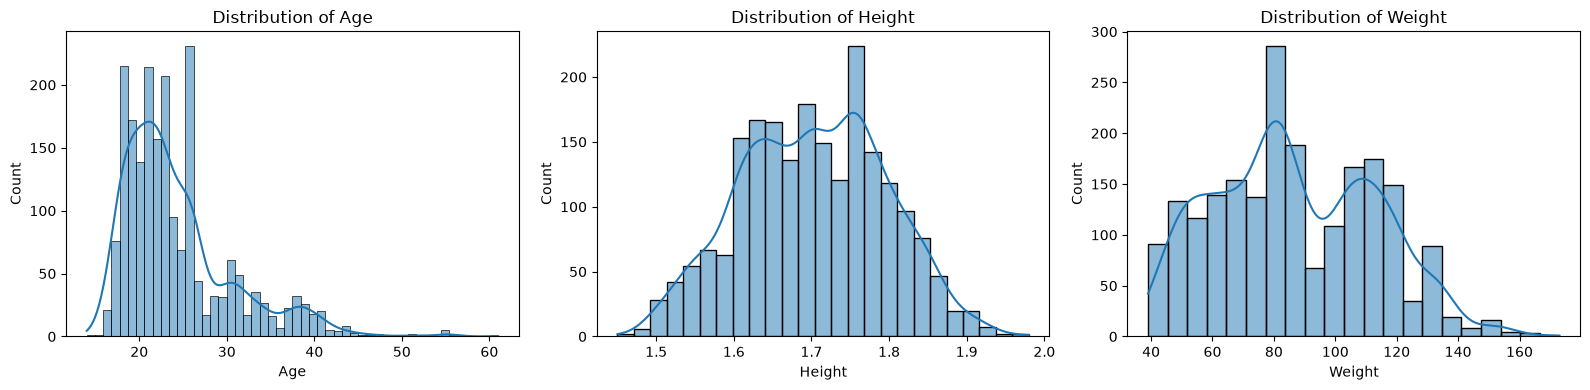

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Age', 'Height', 'Weight']):
    sns.histplot(df_clean[col], kde=True, ax=ax)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

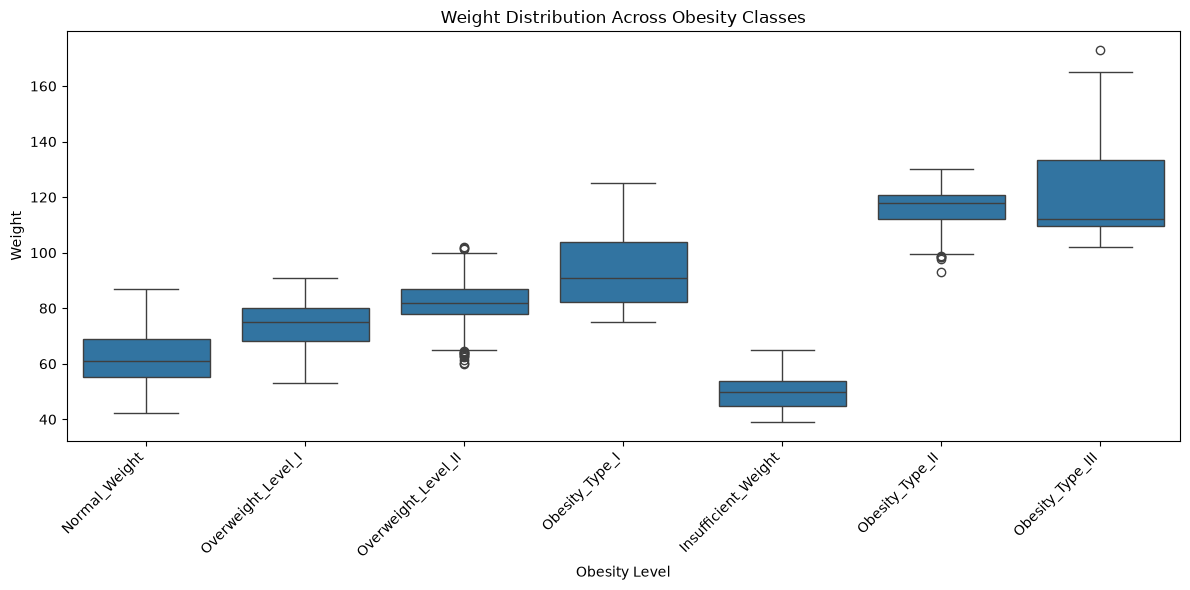

In [10]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_clean, x=TARGET, y='Weight')
plt.title('Weight Distribution Across Obesity Classes')
plt.xlabel('Obesity Level')
plt.ylabel('Weight')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

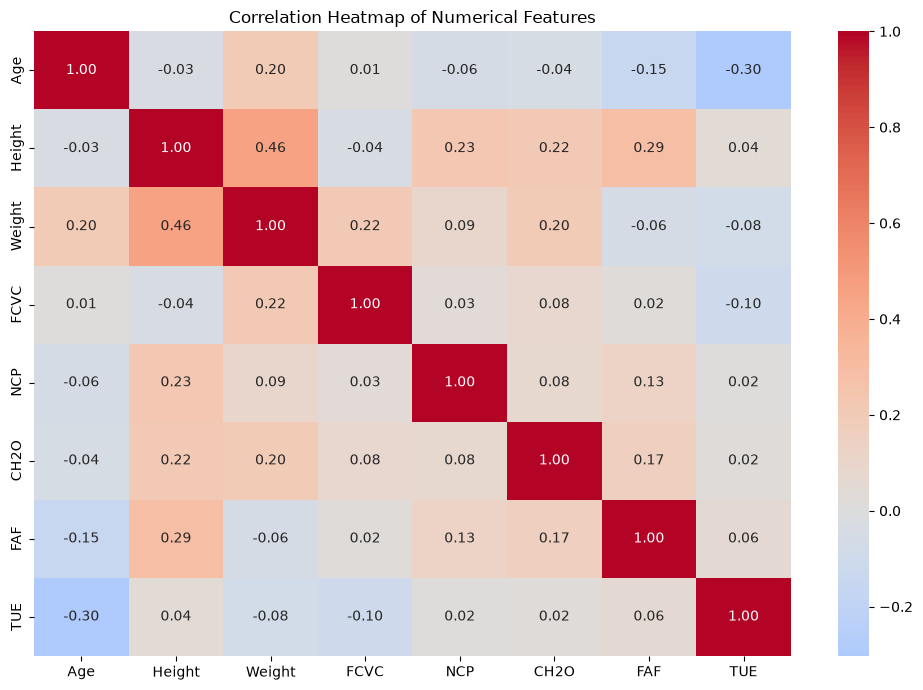

In [11]:
numeric_for_corr = df_clean.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

## 7. Define predictors and preprocessing
The dataset mixes numerical and categorical variables. Numerical features are standardized and categorical features are one-hot encoded.

The preprocessing object is fitted **inside each model pipeline and only on the training data**, which prevents leakage.

In [12]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print('Numerical features:', numeric_features)
print('Categorical features:', categorical_features)
print('Number of predictors:', X.shape[1])

Numerical features: ['Age', 'Height', 'Weight', 'FCVC', 'NCP', 'CH2O', 'FAF', 'TUE']
Categorical features: ['Gender', 'family_history_with_overweight', 'FAVC', 'CAEC', 'SMOKE', 'SCC', 'CALC', 'MTRANS']
Number of predictors: 16


In [13]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

print('Preprocessor created successfully.')

Preprocessor created successfully.


## 8. Stratified train/test split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

split_check = pd.concat([
    y_train.value_counts(normalize=True).rename('Train proportion'),
    y_test.value_counts(normalize=True).rename('Test proportion')
], axis=1).sort_index()
display(split_check.round(3))

X_train: (1669, 16)
X_test : (418, 16)
y_train: (1669,)
y_test : (418,)


,Train proportion,Test proportion
NObeyesdad,,
Insufficient_Weight,0.128,0.127
Normal_Weight,0.135,0.136
Obesity_Type_I,0.168,0.167
Obesity_Type_II,0.142,0.144
Obesity_Type_III,0.155,0.156
Overweight_Level_I,0.132,0.132
Overweight_Level_II,0.139,0.139


## 9. Define the five required models


In [16]:
model_estimators = {
    'Logistic Regression': LogisticRegression(max_iter=3000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Naive Bayes': GaussianNB(),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42)
}

models = {
    name: Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', estimator)
    ])
    for name, estimator in model_estimators.items()
}

print('Models prepared:', list(models.keys()))

Models prepared: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Naive Bayes', 'Support Vector Machine']


## 10. Evaluation function
Because this is a multiclass problem:
- Precision, Recall, and F1 use a **weighted average**.
- AUC uses multiclass **One-vs-Rest (OvR)** with a weighted average.
- MCC is calculated directly from the multiclass predictions.

The function also returns predictions and probabilities for later inspection.

In [17]:
class_order = np.array(sorted(y.unique()))

def evaluate_model(model_name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # predict_proba is available for all five configured models
    y_prob_raw = model.predict_proba(X_test)
    model_classes = model.named_steps['classifier'].classes_

    # Reorder probability columns to a common class order for fair AUC computation
    prob_df = pd.DataFrame(y_prob_raw, columns=model_classes)
    y_prob = prob_df[class_order].to_numpy()
    y_true_bin = label_binarize(y_test, classes=class_order)

    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_true_bin, y_prob, multi_class='ovr', average='weighted'),
        'Precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'F1 Score': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'MCC': matthews_corrcoef(y_test, y_pred)
    }
    return metrics, y_pred, y_prob

## 11. Train and evaluate all five models
The loop fits each complete pipeline to the training set and evaluates only on the held-out test set.

In [18]:
results = []
predictions = {}
probabilities = {}
trained_models = {}

for model_name, model in models.items():
    print(f'Training {model_name}...')
    metrics, y_pred, y_prob = evaluate_model(
        model_name, model, X_train, X_test, y_train, y_test
    )
    results.append(metrics)
    predictions[model_name] = y_pred
    probabilities[model_name] = y_prob
    trained_models[model_name] = model

print('All models trained and evaluated.')

Training Logistic Regression...
Training Decision Tree...
Training K-Nearest Neighbors...
Training Naive Bayes...
Training Support Vector Machine...
All models trained and evaluated.


## 12. Required model-comparison table

In [19]:
results_df = pd.DataFrame(results).set_index('Model')
results_df = results_df.sort_values('MCC', ascending=False)
display(results_df.round(4))

,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Decision Tree,0.9330,0.9610,0.9340,0.9330,0.9326,0.9220
Support Vector Machine,0.9115,0.9940,0.9121,0.9115,0.9114,0.8967
Logistic Regression,0.8971,0.9861,0.8950,0.8971,0.8954,0.8800
K-Nearest Neighbors,0.8278,0.9662,0.8204,0.8278,0.8136,0.8017
Naive Bayes,0.5144,0.8391,0.5252,0.5144,0.4650,0.4566


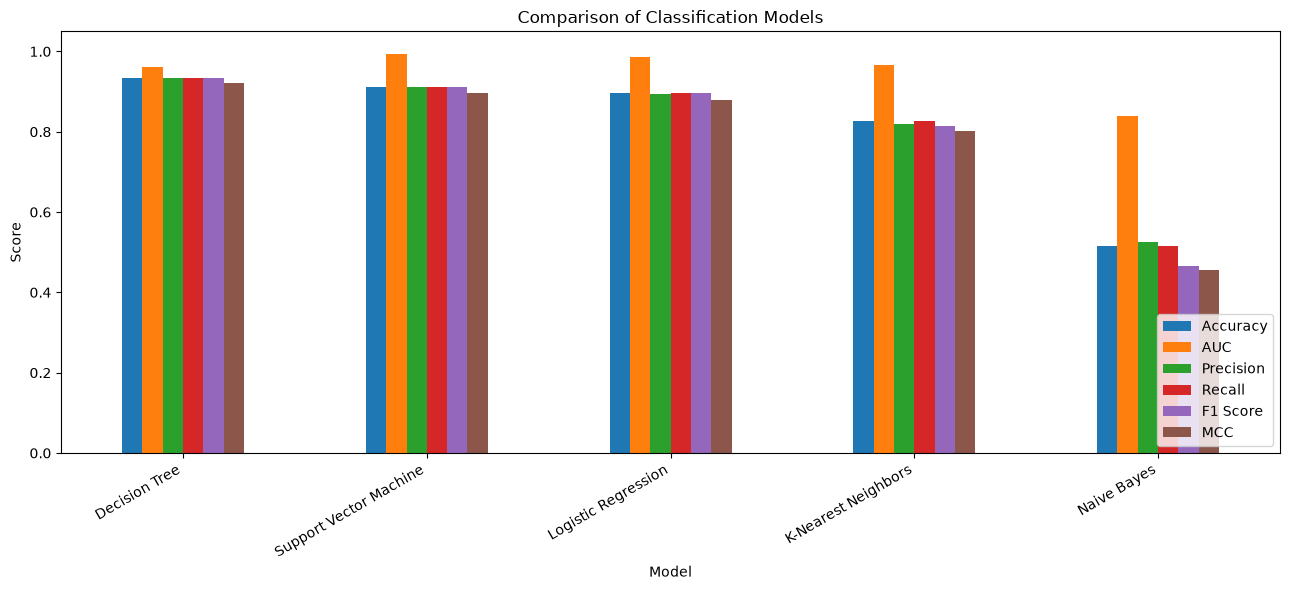

In [20]:
ax = results_df[['Accuracy', 'AUC', 'Precision', 'Recall', 'F1 Score', 'MCC']].plot(
    kind='bar', figsize=(13, 6)
)
ax.set_title('Comparison of Classification Models')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 13. Classification reports
The per-class reports reveal whether an apparently strong overall score hides poor performance for a specific obesity category.

In [21]:
for model_name in models.keys():
    print('=' * 90)
    print(model_name)
    print('=' * 90)
    print(classification_report(y_test, predictions[model_name], zero_division=0))

Logistic Regression
                     precision    recall  f1-score   support

Insufficient_Weight       0.95      1.00      0.97        53
      Normal_Weight       0.84      0.82      0.83        57
     Obesity_Type_I       0.92      0.93      0.92        70
    Obesity_Type_II       0.94      1.00      0.97        60
   Obesity_Type_III       0.98      0.98      0.98        65
 Overweight_Level_I       0.80      0.80      0.80        55
Overweight_Level_II       0.82      0.72      0.77        58

           accuracy                           0.90       418
          macro avg       0.89      0.89      0.89       418
       weighted avg       0.89      0.90      0.90       418

Decision Tree
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.96      0.97        53
      Normal_Weight       0.83      0.91      0.87        57
     Obesity_Type_I       0.94      0.94      0.94        70
    Obesity_Type_II       0.98      0.98      0

## 14. Confusion matrices
A confusion matrix is displayed for every required model.

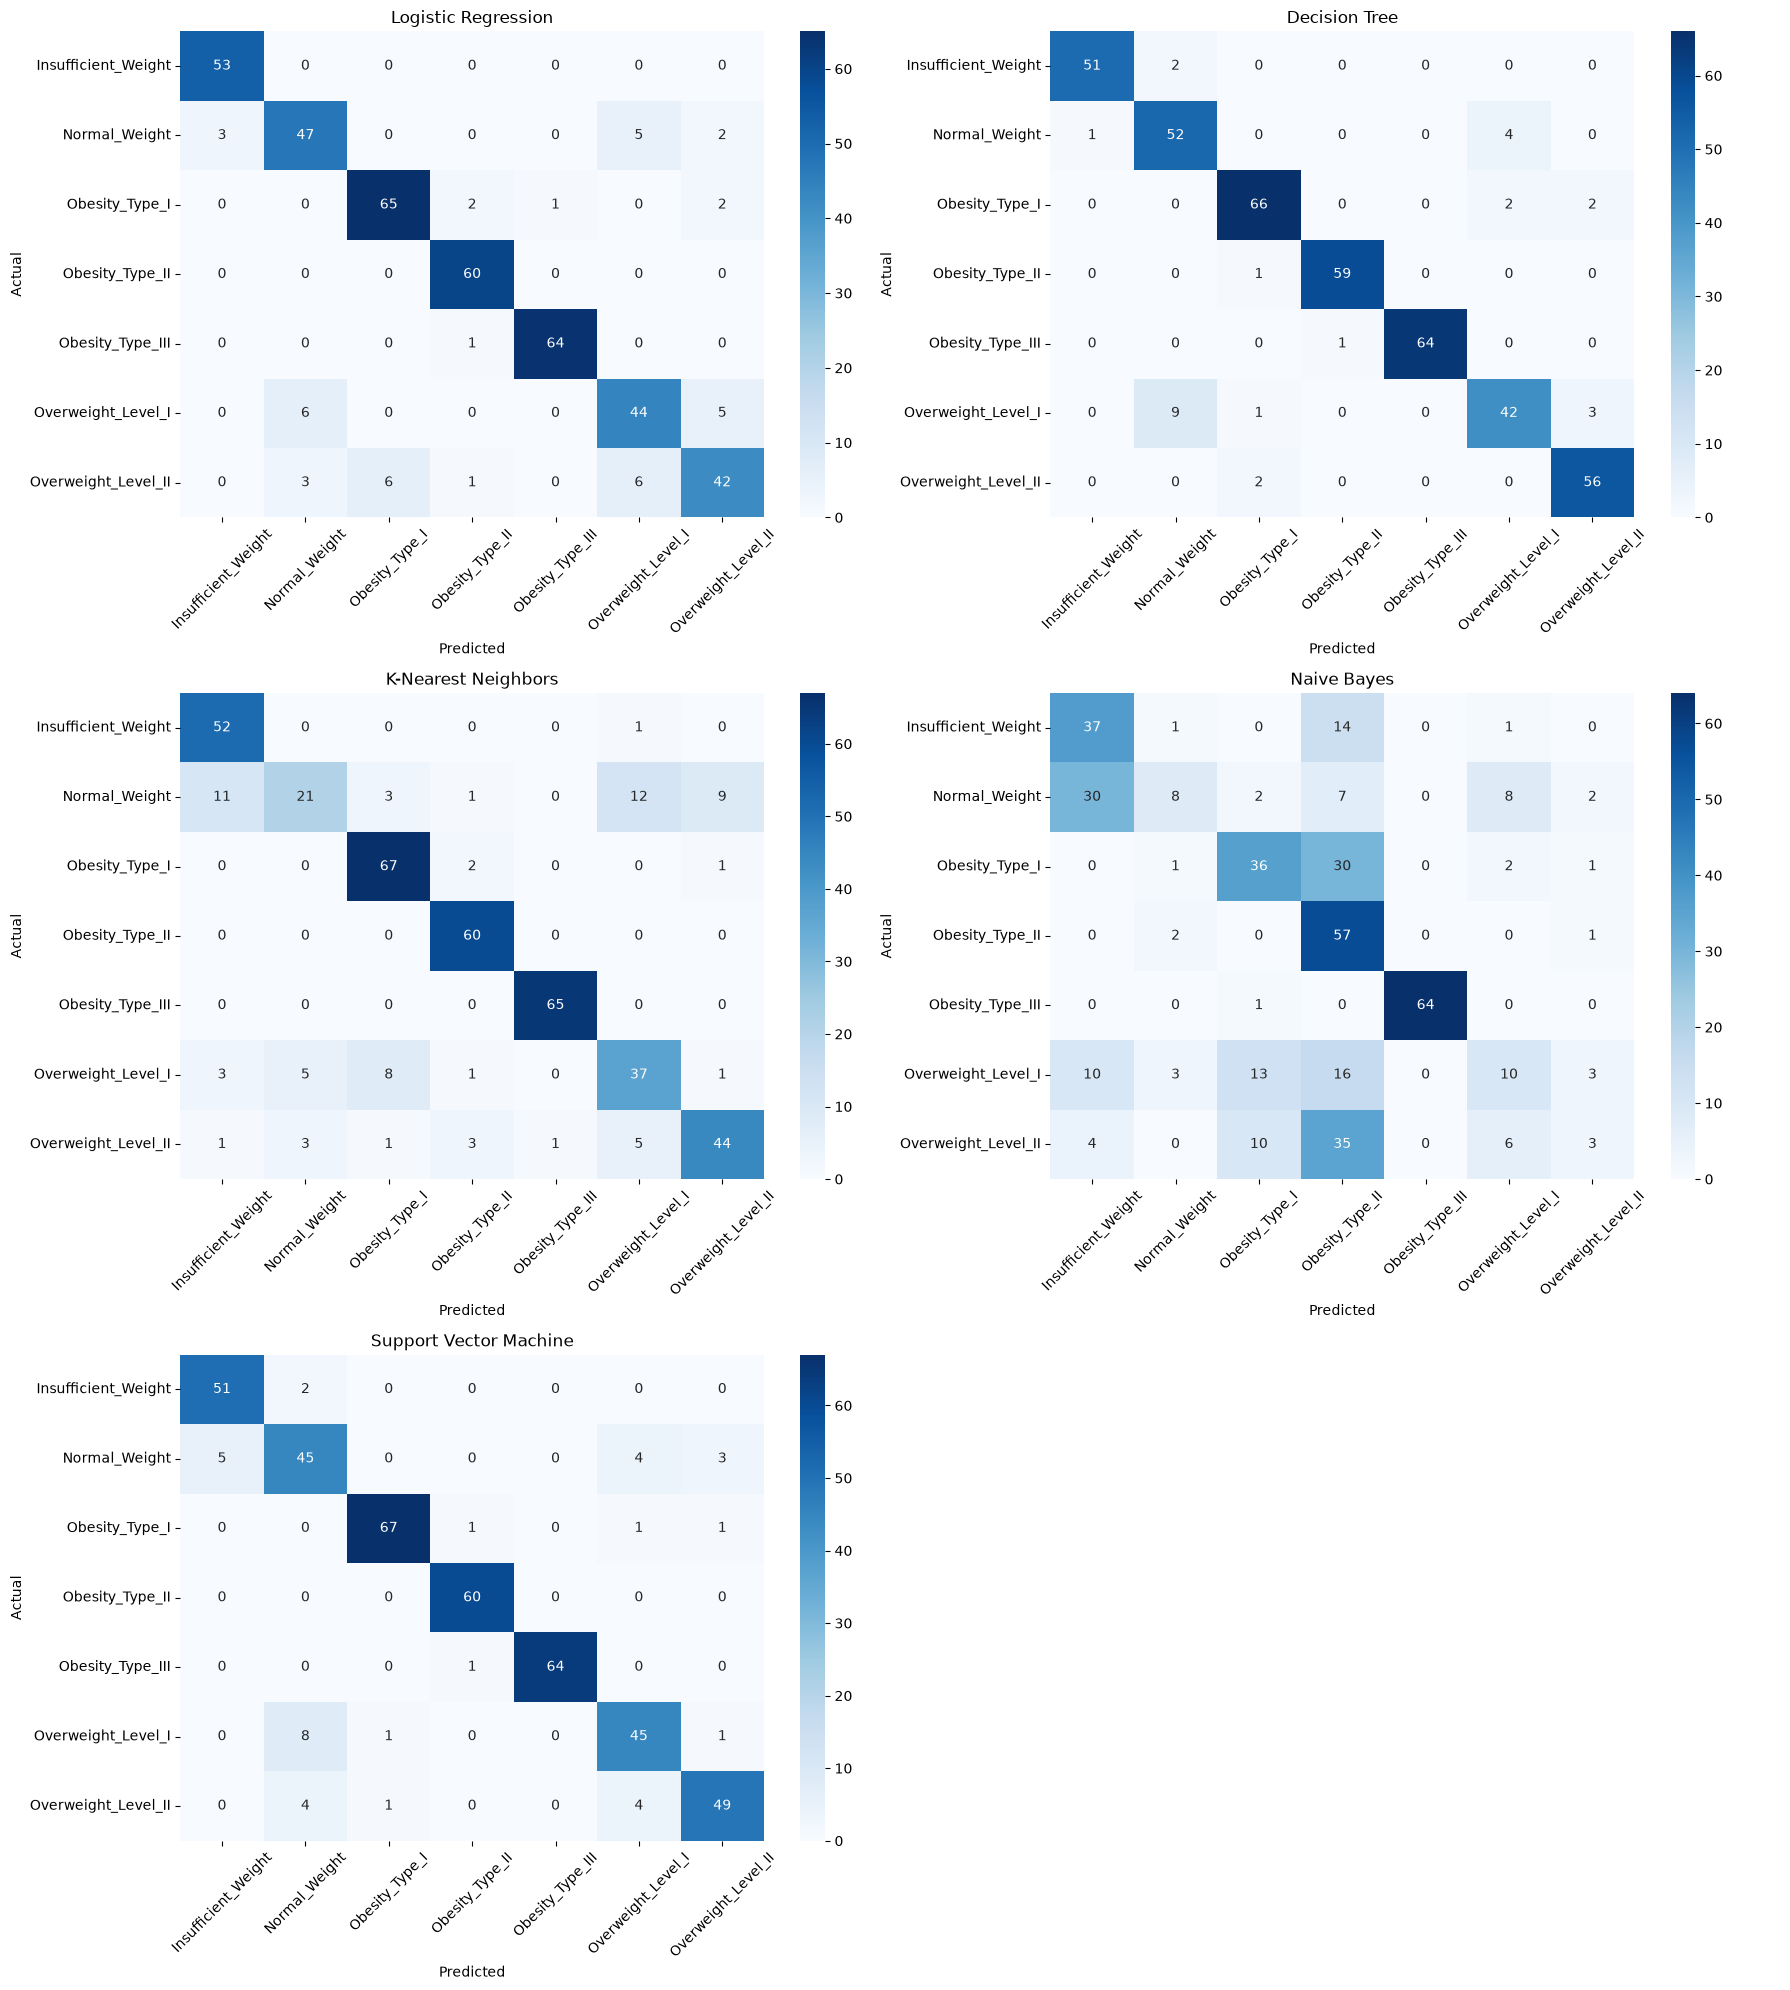

In [22]:
fig, axes = plt.subplots(3, 2, figsize=(18, 20))
axes = axes.flatten()

for ax, model_name in zip(axes, models.keys()):
    cm = confusion_matrix(y_test, predictions[model_name], labels=class_order)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_order, yticklabels=class_order)
    ax.set_title(model_name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

# Hide unused subplot
for ax in axes[len(models):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## 15. Identify the strongest model


In [23]:
best_model_name = results_df.index[0]
best_row = results_df.loc[best_model_name]

print('Best model by MCC:', best_model_name)
print(f"MCC: {best_row['MCC']:.4f}")
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"AUC: {best_row['AUC']:.4f}")
print(f"F1 Score: {best_row['F1 Score']:.4f}")

Best model by MCC: Decision Tree
MCC: 0.9220
Accuracy: 0.9330
AUC: 0.9610
F1 Score: 0.9326


## 16. Data-driven observations for the report


In [24]:
ranked = results_df.reset_index()
print('MODEL PERFORMANCE OBSERVATIONS')
print('-' * 70)
for i, row in ranked.iterrows():
    print(
        f"{i+1}. {row['Model']}: Accuracy={row['Accuracy']:.4f}, "
        f"AUC={row['AUC']:.4f}, F1={row['F1 Score']:.4f}, MCC={row['MCC']:.4f}"
    )

print('\nSuggested conclusion structure:')
print(
    f"{best_model_name} ranked highest by MCC on the held-out test sample. "
    "Interpret this together with AUC, weighted F1, and the confusion matrix before writing the final conclusion."
)

MODEL PERFORMANCE OBSERVATIONS
----------------------------------------------------------------------
1. Decision Tree: Accuracy=0.9330, AUC=0.9610, F1=0.9326, MCC=0.9220
2. Support Vector Machine: Accuracy=0.9115, AUC=0.9940, F1=0.9114, MCC=0.8967
3. Logistic Regression: Accuracy=0.8971, AUC=0.9861, F1=0.8954, MCC=0.8800
4. K-Nearest Neighbors: Accuracy=0.8278, AUC=0.9662, F1=0.8136, MCC=0.8017
5. Naive Bayes: Accuracy=0.5144, AUC=0.8391, F1=0.4650, MCC=0.4566

Suggested conclusion structure:
Decision Tree ranked highest by MCC on the held-out test sample. Interpret this together with AUC, weighted F1, and the confusion matrix before writing the final conclusion.


## 17. Save trained pipelines
Each `.joblib` file includes both preprocessing and the trained classifier for thr purpose of Streamlit

In [25]:
os.makedirs('model', exist_ok=True)

safe_names = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'K-Nearest Neighbors': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib'
}

for model_name, fitted_model in trained_models.items():
    output_path = os.path.join('model', safe_names[model_name])
    joblib.dump(fitted_model, output_path)
    print('Saved:', output_path)

Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/knn.joblib
Saved: model/naive_bayes.joblib
Saved: model/svm.joblib


## 18. Export held-out test data

In [26]:
test_data = X_test.copy()
test_data[TARGET] = y_test.values
test_data.to_csv('test_data.csv', index=False)

print('Saved test_data.csv')
print('Shape:', test_data.shape)
display(test_data.head())

Saved test_data.csv
Shape: (418, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
1153,Female,19.955257,1.589100,72.713611,yes,no,3.00000,3.856434,Sometimes,no,2.000000,no,1.324170,1.000000,Sometimes,Public_Transportation,Overweight_Level_II
132,Male,30.000000,1.770000,109.000000,yes,yes,3.00000,3.000000,Sometimes,no,1.000000,no,2.000000,0.000000,Sometimes,Automobile,Obesity_Type_I
1923,Female,20.601222,1.738717,128.114161,yes,yes,3.00000,3.000000,Sometimes,no,1.797041,no,1.427413,0.966181,Sometimes,Public_Transportation,Obesity_Type_III
846,Female,16.950499,1.603501,65.000000,yes,yes,2.96008,1.000000,Sometimes,no,2.000000,yes,0.736032,1.344072,no,Public_Transportation,Overweight_Level_I
1246,Male,29.506287,1.826970,108.751502,yes,yes,2.00000,2.877583,Sometimes,no,2.358038,no,0.877295,1.817146,Sometimes,Automobile,Obesity_Type_I


## 19. Verify saved model reproducibility


In [27]:
best_model_path = os.path.join('model', safe_names[best_model_name])
reloaded_model = joblib.load(best_model_path)
reloaded_pred = reloaded_model.predict(X_test)

same_predictions = np.array_equal(reloaded_pred, predictions[best_model_name])
print('Reloaded model:', best_model_path)
print('Predictions identical after reload:', same_predictions)

Reloaded model: model/decision_tree.joblib
Predictions identical after reload: True


## 20. Export metrics for README / Streamlit

In [28]:
results_df.round(6).to_csv('model_comparison.csv')
print('Saved model_comparison.csv')
display(results_df.round(4))

Saved model_comparison.csv


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Decision Tree,0.9330,0.9610,0.9340,0.9330,0.9326,0.9220
Support Vector Machine,0.9115,0.9940,0.9121,0.9115,0.9114,0.8967
Logistic Regression,0.8971,0.9861,0.8950,0.8971,0.8954,0.8800
K-Nearest Neighbors,0.8278,0.9662,0.8204,0.8278,0.8136,0.8017
Naive Bayes,0.5144,0.8391,0.5252,0.5144,0.4650,0.4566
